# LLMOps: version prompts, evaluate behavior and trace requests

This worked reference is validated on CPU. Accelerator compatibility requires a separate source review and target execution receipt. Use the execution matrix to review device selection and data ownership before adapting a separate target program.

- Version the prompt, local retriever, adapter and corpus
- Evaluate heterogeneous cases by stable ID
- Trace retrieval, prompt, generation and infrastructure outcomes
- Localize one failure at each boundary
- Compare candidate policies on identical IDs and denominators

A prompt edit improves ordinary answers but makes the system confidently answer a question its documents cannot support. Run a bounded local retrieval and deterministic model adapter, trace each stage, and compare candidates on a frozen set of stable case IDs without a paid API.

## The idea

An LLM application combines prompts, retrieved context, a model boundary and infrastructure outcomes. This small local adapter executes retrieval and generation so a trace can show where an answer failed. Its deterministic outputs teach instrumentation and release policy; they are not evidence about a commercial or general-purpose LLM.

## Trace a response through the system that produced it

Follow one request from case inventory to trace. Each record ties a stable case ID to the candidate configuration, prompt, index, retrieved document IDs, adapter input and output, status, and evaluator result. In the baseline run, refund-order-204 fails because retrieval did not deliver the required evidence; case-sensitive-refund-77 reaches the generation boundary but returns a response that breaks its contract; return-ambiguous-9 times out before retrieval or generation. Those three observations point to different owners and fixes. Start with the failed stage in the trace instead of changing the prompt whenever a score drops. This is an executed deterministic local adapter, so its trace explains the fixture run only.

$$
\mathcal T_i=(\mathrm{case}_i,\mathrm{prompt\ id},\mathrm{retriever\ id},\mathrm{model\ id},\mathrm{context}_i,\mathrm{response}_i,\mathrm{evaluator\ id})
$$

### Pause and reason

Why retain the retrieved context in an error trace?

<details><summary>Compare your reasoning</summary>

It distinguishes missing or wrong evidence from generation or instruction-following errors. Without that context, the same final response can support several incompatible diagnoses.

</details>

## Version the application boundary

A response depends on several versioned pieces, so give each its own identity. The baseline trace names prompt-v1-careless, index-v1-complete and extractive-local-adapter-v1; its configuration hash is 479424bdd62be245. The candidate uses prompt-v2-grounded and index-v2-complete with the same adapter, under hash 7916d53bb58408ce. Keeping these identities in each trace lets a reviewer ask what actually changed. The recorded retrieval context and adapter response then show how that configuration handled a particular case. For a hosted deployment, also resolve the exact model, tokenizer and serving configuration before comparing runs.

## Define cases before changing the prompt

The $5$-case inventory is frozen before the candidate runs: hours-west-17 checks a supported answer, refund-order-204 needs a specific refund document, return-ambiguous-9 exercises a timeout, unsupported-tax-2 requires abstention, and case-sensitive-refund-77 checks answer formatting. The evaluator fixes each expected answer and allowed evidence ID in advance. That means both candidates are scored on the same $5$ IDs, rather than on whichever requests happened to return. The exact contract is practical for this tiny corpus: it catches a missing document or malformed abstention, but it is not a general semantic judge. Before tuning, list the cases that can change a release decision and the evidence each requires.

## Read the rare-case failure

Read the baseline failures by stage. It passes only hours-west-17, so $1$ of $5$ cases passes ($0.2$). refund-order-204 lacks its supporting retrieval result; unsupported-tax-2 fails because the careless prompt encourages guessing; case-sensitive-refund-77 has a malformed answer; return-ambiguous-9 times out. The grounded candidate changes the prompt, index and timeout setting, then passes all $5$ identical IDs ($5/5$). This result says the revised fixture configuration satisfies this fixture's contracts. It does not isolate which change caused each improvement: a separate retrieval-only run scores $0.8$, and a prompt-only run with baseline retrieval and infrastructure settings scores $3/5$. Use per-case traces and controlled changes to locate cause before making a broad claim about a candidate.

## Trace enough to diagnose, without retaining everything

A useful trace contains enough context to locate a failure: which document IDs were retrieved, what prompt and context reached the adapter, what it returned, and whether execution completed. The sample trace for hours-west-17 records doc-hours and the sentence about Monday through Friday, $09{:}00$ to $17{:}00$; the adapter returns that same sentence and the case passes. That is enough to connect the expected evidence to the response. The fixture stores only its own documents. In a real service, prompts and retrieved text can contain private data, so choose redaction, access and retention rules before collecting traces.

## Add the production cases deliberately

Expand the frozen cases to cover missing or contradictory context, multilingual requests, long contexts, prompt injection inside retrieved text, malformed tool arguments, unsupported tools, timeouts and rate limits. For example, retrieved instructions should be treated as untrusted document content, while tool permissions come from an external allowlist. Keep held-out and human-reviewed examples separate from cases used to tune prompts, so the same examples do not serve as both target and evidence of success. If a language-model judge is used, record its version and rubric and compare it with human labels; disagreement identifies cases to inspect.

## Measure serving work in the right units

Choose measurements that match the work being served. Separate prefill from decode, then record time to first token, output tokens per second, completion rate, tail latency and request cost for stated context lengths and concurrency. A whitespace count is not a provider token count, so use the provider's tokenizer and pricing for a cost estimate. Set timeout and retry budgets, and exercise the fallback path. The local adapter records response accounting for the fixture; it cannot establish hosted throughput or provider cost.

**Run the bounded local adapter experiment**

```python
Save the lesson experiment as llmops_local.py and run: python llmops_local.py
```

**Expected:** Executes local retrieval, prompt/model adapter boundaries, stable-ID scoring, diagnostics and candidate comparison. No MLflow installation or model API is required.

## A missing response is an evaluation failure

The scorer expects one outcome for each of the $5$ frozen IDs. It can join responses by ID even if they arrive out of order, but it rejects duplicate or unknown IDs and keeps a timeout under its original case ID. If a response is missing, that case remains in the denominator and the run cannot quietly improve its score by omitting a failure. In the incomplete-run example, scoring is rejected; dividing only the returned cases would misleadingly report $0.25$. When comparing two runs, first confirm the expected IDs are all accounted for, then interpret the numerator and denominator.

## Run the example

In [1]:
# Bounded local LLMOps adapter. The trace records actual local retrieval and generation calls.
# It uses no MLflow service, network, paid API, or canned per-case answer array.
import hashlib, json

def fingerprint(value):
    raw=json.dumps(value,sort_keys=True,separators=(',',':')).encode()
    return hashlib.sha256(raw).hexdigest()[:16]

corpus={
 'doc-hours':'Support is open Monday through Friday, 09:00 to 17:00.',
 'doc-refund':'Refunds are available within 30 days of purchase.',
 'doc-return':'Return items with the original receipt.'
}
# Stable heterogeneous case IDs and frozen expected outcomes.
cases=[
 {'id':'hours-west-17','query':'When is support open?','expected':'Support is open Monday through Friday, 09:00 to 17:00.','evidence':'doc-hours','supported':True},
 {'id':'refund-order-204','query':'What is the refund period?','expected':'Refunds are available within 30 days of purchase.','evidence':'doc-refund','supported':True},
 {'id':'return-ambiguous-9','query':'Can I return an item?','expected':'Return items with the original receipt.','evidence':'doc-return','supported':True},
 {'id':'unsupported-tax-2','query':'What is the tax rate?','expected':'','evidence':None,'supported':False},
 {'id':'case-sensitive-refund-77','query':'How many days for a refund?','expected':'Refunds are available within 30 days of purchase.','evidence':'doc-refund','supported':True},
]

def retrieve(query,index,excluded=()):
    def normalize(word):
        word=word.lower().strip('?.!,')
        return word[:-1] if len(word)>4 and word.endswith('s') else word
    terms={normalize(w) for w in query.split() if len(w)>3}
    ranked=[]
    for doc_id,text in index.items():
        if doc_id in excluded: continue
        words={normalize(w) for w in text.split()}
        overlap=len(terms & words)
        if overlap: ranked.append((overlap,doc_id,text))
    ranked.sort(key=lambda row:(-row[0],row[1]))
    return ranked[0][1:] if ranked else (None,None)

def local_model_adapter(prompt,context):
    # The prompt is the actual input contract consumed at this model boundary.
    if context is None:
        if 'ABSTAIN_WHEN_EMPTY' in prompt: return ''
        return 'The answer is probably 15 percent.'
    if 'FORMAT_REFUND' in prompt and 'refund' in context.lower(): return 'Answer: '+context
    return context

def run_case(case,candidate):
    trace={'case_id':case['id'],'candidate_id':candidate['id'],'config_hash':candidate['config_hash'],
           'prompt_id':candidate['prompt_id'],'index_id':candidate['index_id'],'model_adapter_id':candidate['model_id']}
    # Simulated infrastructure fault is a transport outcome, not a model answer.
    if case['id'] in candidate['timeouts']:
        trace.update(status='timeout',retrieved_id=None,context=None,response=None,diagnosis='infrastructure')
        return {'id':case['id'],'status':'timeout','response':None},json.dumps(trace,sort_keys=True)
    retrieved_id,context=retrieve(case['query'],candidate['index'],candidate['excluded_docs']+tuple(candidate['case_excluded'].get(case['id'],())))
    trace.update(retrieval={'query':case['query'],'retrieved_id':retrieved_id,'context':context})
    response=local_model_adapter(candidate['prompt'],context)
    trace['generation']={'prompt':candidate['prompt'],'model_input_context':context,'response':response}
    if context is None:
        diagnosis='retrieval' if case['supported'] else ('generation' if response else 'ok')
    elif case['supported'] and retrieved_id!=case['evidence']:
        diagnosis='retrieval'
    elif case['supported'] and response!=case['expected']:
        diagnosis='generation'
    elif not case['supported'] and response:
        diagnosis='generation'
    else: diagnosis='ok'
    trace.update(status='complete',diagnosis=diagnosis)
    return {'id':case['id'],'status':'complete','response':response,'retrieved_id':retrieved_id},json.dumps(trace,sort_keys=True)

def collect_by_id(expected_ids,responses):
    expected=set(expected_ids); got={}
    for response in responses:
        cid=response['id']
        if cid not in expected: raise ValueError('unknown case ID: '+cid)
        if cid in got: raise ValueError('duplicate response ID: '+cid)
        got[cid]=response
    missing=expected-got.keys()
    if missing: raise ValueError('missing response IDs: '+','.join(sorted(missing)))
    return got

def score(cases,responses):
    paired=collect_by_id([c['id'] for c in cases],responses)
    outcomes=[]
    for case in cases:
        result=paired[case['id']]
        passed=(result['status']=='complete' and
                (result['response']==case['expected']) and
                (not case['supported'] or result['retrieved_id']==case['evidence']))
        outcomes.append({'id':case['id'],'passed':passed,'status':result['status']})
    return {'count':len(outcomes),'passed':sum(x['passed'] for x in outcomes),
            'fraction':sum(x['passed'] for x in outcomes)/len(outcomes),'cases':outcomes}

def make_candidate(cid,prompt_id,prompt,index_id,index,excluded=(),timeouts=(),case_excluded=None):
    model_id='extractive-local-adapter-v1'
    config_hash=fingerprint({'prompt_id':prompt_id,'prompt':prompt,'index_id':index_id,
                             'index_hash':fingerprint(index),'model_id':model_id,
                             'excluded_docs':list(excluded),'timeouts':list(timeouts),
                             'case_excluded':case_excluded or {}})
    return {'id':cid,'prompt_id':prompt_id,'prompt':prompt,'index_id':index_id,'index':index,
            'model_id':model_id,'config_hash':config_hash,'excluded_docs':tuple(excluded),'timeouts':tuple(timeouts),
            'case_excluded':case_excluded or {}}

baseline=make_candidate('candidate-baseline-01','prompt-v1-careless','ANSWER_EVEN_WITHOUT_EVIDENCE FORMAT_REFUND',
                        'index-v1-complete',corpus,case_excluded={'refund-order-204':('doc-refund',)},
                        timeouts=('return-ambiguous-9',))
candidate=make_candidate('candidate-grounded-02','prompt-v2-grounded','ABSTAIN_WHEN_EMPTY',
                         'index-v2-complete',corpus)
runs=[]
for config in (baseline,candidate):
    responses=[]; traces=[]
    for case in cases:
        response,trace=run_case(case,config); responses.append(response); traces.append(trace)
    # Simulate asynchronous completion: pair by ID, never by list position.
    responses=list(reversed(responses))
    summary=score(cases,responses)
    runs.append((summary,traces,responses))

before,trace_before,responses_before=runs[0]
after,trace_after,responses_after=runs[1]
assert before['count']==5 and before['fraction']==.2
assert after['count']==5 and after['fraction']==1.
assert [x['id'] for x in before['cases']]==[x['id'] for x in after['cases']]
assert [x['id'] for x in cases]==[json.loads(x)['case_id'] for x in trace_after]
assert baseline['model_id']==candidate['model_id']
assert baseline['config_hash']!=candidate['config_hash']
# Pairing handles reordering; duplicates and incomplete response inventories are rejected.
assert len(collect_by_id([c['id'] for c in cases],responses_after))==5
for damaged in (responses_after[:-1],responses_after+[responses_after[0]],responses_after+[{'id':'invented-case','status':'complete','response':'x'}]):
    try: collect_by_id([c['id'] for c in cases],damaged)
    except ValueError: pass
    else: raise AssertionError('bad case-ID inventory accepted')

def diagnostic(trace,case):
    if trace['diagnosis']=='infrastructure': return 'Infrastructure: timeout occurred before retrieval or generation.'
    if trace['diagnosis']=='retrieval': return 'Retrieval: the required evidence did not reach the model boundary.'
    if trace['diagnosis']=='generation': return 'Generation: inspect the recorded prompt, correct context and adapter response.'
    return 'No failure observed for this case.'
by_id={t['case_id']:t for t in (json.loads(x) for x in trace_before)}
for cid in ('refund-order-204','case-sensitive-refund-77','return-ambiguous-9'):
    case=next(c for c in cases if c['id']==cid)
    print(cid+':',diagnostic(by_id[cid],case))
print('serialized local retrieval+generation trace sample:',trace_before[0])
print('baseline:',json.dumps(before,sort_keys=True))
print('candidate:',json.dumps(after,sort_keys=True))
print('same frozen case IDs and denominator:',len(cases),[c['id'] for c in cases])
print('baseline candidate identity:',baseline['id'],baseline['prompt_id'],baseline['index_id'],baseline['model_id'],baseline['config_hash'])
print('candidate identity:',candidate['id'],candidate['prompt_id'],candidate['index_id'],candidate['model_id'],candidate['config_hash'])
print('Traces are actual deterministic local adapter executions, not hosted LLM or general quality evidence.')

refund-order-204: Retrieval: the required evidence did not reach the model boundary.
case-sensitive-refund-77: Generation: inspect the recorded prompt, correct context and adapter response.
return-ambiguous-9: Infrastructure: timeout occurred before retrieval or generation.
serialized local retrieval+generation trace sample: {"candidate_id": "candidate-baseline-01", "case_id": "hours-west-17", "config_hash": "479424bdd62be245", "diagnosis": "ok", "generation": {"model_input_context": "Support is open Monday through Friday, 09:00 to 17:00.", "prompt": "ANSWER_EVEN_WITHOUT_EVIDENCE FORMAT_REFUND", "response": "Support is open Monday through Friday, 09:00 to 17:00."}, "index_id": "index-v1-complete", "model_adapter_id": "extractive-local-adapter-v1", "prompt_id": "prompt-v1-careless", "retrieval": {"context": "Support is open Monday through Friday, 09:00 to 17:00.", "query": "When is support open?", "retrieved_id": "doc-hours"}, "status": "complete"}
baseline: {"cases": [{"id": "hours-wes

Expected: Executed local candidate comparison: baseline 1/5 (0.2), candidate 5/5 (1.0), same five stable case IDs and denominator. Traces expose the omitted refund document, correct context with a malformed generated response, unsupported-question hallucination, and a pre-retrieval timeout. Shuffled responses pair by ID; missing, duplicate and unknown IDs are rejected. This adapter is not a hosted LLM or quality benchmark.

## The unsupported case changes the release decision

Predict: How can a candidate pass 90% overall and still fail every unsupported case?

CPU computation; rerun to recompute the data.

Run the cells below to produce the figure, then follow the walkthrough beneath it.

In [2]:
visual_data={'kind':'bar','labels':['baseline (5 cases)','grounded candidate (5 cases)'],'xlabel':'candidate (same stable IDs and denominator)','ylabel':'fixture pass fraction','series':[{'label':'observed pass fraction','y':[before['fraction'],after['fraction']]}]}

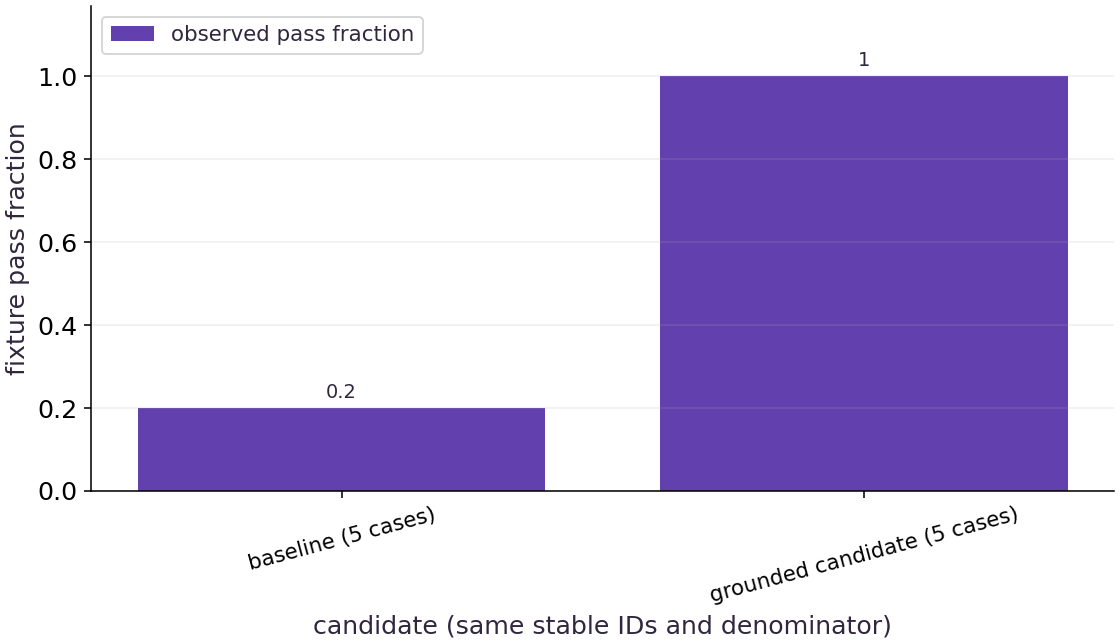

In [3]:
# Render the figure from the data computed above. Change the data experiment and rerun.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 13, 'axes.labelcolor': '#30273e', 'text.color': '#30273e'})
def draw_panel(ax, data):
    import numpy as np
    palette = ['#6240ad', '#087c83', '#bc532c', '#405d9d']
    kind = data['kind']
    if kind in ('heatmap', 'field'):
        a = np.asarray(data['values'], dtype=float)
        assert a.ndim == 2 and np.isfinite(a).all()
        kw = {'cmap': 'PuOr' if data.get('diverging') else 'Purples', 'aspect': 'auto'}
        if kind == 'field':
            kw.update(extent=data['extent'], origin='lower', vmin=0, vmax=1)
        elif data.get('diverging'):
            limit = max(float(np.abs(a).max()), 1e-10)
            kw.update(vmin=-limit, vmax=limit)
        if data.get('scale') == 'probability' or data['unit'] in ('attention weight', 'next-token probability', 'masked-token probability'):
            kw.update(vmin=0, vmax=1)
        categorical = data.get('scale') == 'categorical' or any(name in data['unit'] for name in ('device ID','program ID'))
        if categorical:
            from matplotlib.colors import ListedColormap, BoundaryNorm
            from matplotlib import colormaps
            ids=np.unique(a).astype(int)
            boundaries=np.r_[ids[0]-.5,(ids[:-1]+ids[1:])/2,ids[-1]+.5]
            kw.update(cmap=ListedColormap([colormaps['tab20'](i) for i in range(len(ids))]), norm=BoundaryNorm(boundaries,len(ids)))
        im = ax.imshow(a, **kw)
        ax.figure.colorbar(im, ax=ax, shrink=0.8, label=data['unit'], **({'ticks':ids} if categorical else {}))
        if kind == 'heatmap':
            if a.size <= 32:
                mid = (float(a.min()) + float(a.max())) / 2
                for (i, j), value in np.ndenumerate(a):
                    rgb=im.cmap(im.norm(value))[:3]
                    luminance=sum(c*w for c,w in zip(rgb,[0.2126,0.7152,0.0722]))
                    ax.text(j, i, f'{value:.3g}', ha='center', va='center', fontsize=11,
                            color='white' if luminance < 0.5 else '#20202c')
            ax.set_xticks(range(a.shape[1]), data.get('columns', [str(i) for i in range(a.shape[1])]))
            ax.set_yticks(range(a.shape[0]), data.get('rows', [str(i) for i in range(a.shape[0])]))
            if a.shape[1] > 5: ax.tick_params(axis='x', labelsize=11)
        else:
            pts = np.asarray(data['points']); labels = np.asarray(data['labels'])
            for label, marker in [(0, 'o'), (1, '^')]:
                selected = pts[labels == label]
                ax.scatter(selected[:, 0], selected[:, 1], label=f'observed label {label}', marker=marker,
                           s=38, facecolors='white' if label == 0 else '#f4b547', edgecolors='#272238', linewidths=1)
            ax.legend(loc='upper left', fontsize=10)
    elif kind in ('line', 'bar'):
        series = data['series']
        x = np.asarray(data.get('x', list(range(len(data.get('labels', []))))))
        assert len(x) and np.isfinite(x).all()
        for i, s in enumerate(series):
            y = np.asarray(s['y'], dtype=float)
            assert y.shape == x.shape and np.isfinite(y).all(), s['label']
            if data.get('yscale') == 'log': assert (y > 0).all()
            if kind == 'line':
                ax.plot(x, y, color=palette[i % len(palette)], label=s['label'], linewidth=2.3,
                        linestyle=['-', '--', '-.', ':'][i % 4], marker='o' if len(x) <= 25 else None, markersize=3)
            else:
                width = 0.78 / len(series)
                bars = ax.bar(x + (i - (len(series)-1)/2)*width, y, width, label=s['label'], color=palette[i % len(palette)])
                if len(x)*len(series) <= 12: ax.bar_label(bars, fmt='%.3g', fontsize=10, padding=3)
        if kind == 'bar':
            ax.set_xticks(x, data['labels'])
            ax.margins(y=0.17)
            if any(len(t) > 13 for t in data['labels']): ax.tick_params(axis='x', labelrotation=15, labelsize=11)
        if data.get('xscale'): ax.set_xscale(data['xscale'])
        if data.get('yscale'): ax.set_yscale(data['yscale'], **({'linthresh':data.get('linthresh',2)} if data['yscale']=='symlog' else {}))
        for marker in data.get('markers',[]):
            ax.scatter([marker['x']],[marker['y']],color='#bc532c',s=45,zorder=5)
            ax.annotate(marker['label'],(marker['x'],marker['y']),xytext=(-85,12),textcoords='offset points',fontsize=10)
        for boundary in data.get('boundaries', []): ax.axvline(boundary, color='#716e7b', linestyle=':', linewidth=1)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(fontsize=11, loc='best')
    elif kind == 'table':
        headers = data['headers']
        rows = data['rows']
        assert headers and rows and all(len(row) == len(headers) for row in rows)
        ax.axis('off')
        table = ax.table(cellText=rows, colLabels=headers, cellLoc='center',
                         loc='center', colWidths=data.get('widths'))
        table.auto_set_font_size(False)
        table.set_fontsize(11)
        table.scale(1, 2.7)
        for (row, _), cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row == 0 else ('#f4f7fb' if row % 2 else '#ffffff'))
            cell.set_text_props(color='#172334', weight='bold' if row == 0 else 'normal')
    elif kind == 'vectors':
        for i, arrow in enumerate(data['arrows']):
            start = np.asarray(arrow['start']); end = np.asarray(arrow['end'])
            ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->','color':palette[i], 'lw':2.8})
            mid=(start+end)/2
            ax.annotate(arrow['label'], mid, xytext=(7,7), textcoords='offset points', color=palette[i])
        ax.set(xlim=(-0.7,4.5),ylim=(-0.7,5),xlabel='first coordinate',ylabel='second coordinate')
        ax.set_aspect('equal'); ax.grid(alpha=0.2)
    elif kind == 'flow':
        from matplotlib.patches import FancyBboxPatch
        nodes=data['nodes']; ax.set(xlim=(0,1),ylim=(0,len(nodes))); ax.axis('off')
        if data.get('layout') == 'merge':
            import textwrap
            for i,label in enumerate(nodes[:3]):
                x=0.02+i*0.33
                ax.add_patch(FancyBboxPatch((x,3.7),0.29,1.0,boxstyle='round,pad=0.015',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(x+0.145,4.2,textwrap.fill(label,20),ha='center',va='center',fontsize=11)
                ax.annotate('',(0.5,2.8),(x+0.145,3.67),arrowprops={'arrowstyle':'->','color':'#6240ad'})
            for y,label in [(2.4,nodes[3]),(0.9,nodes[4])]:
                ax.add_patch(FancyBboxPatch((0.08,y-0.35),0.84,0.7,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
            ax.annotate('',(0.5,1.3),(0.5,2.0),arrowprops={'arrowstyle':'->','color':'#6240ad'})
        else:
            for i, label in enumerate(nodes):
                y=len(nodes)-i-0.5
                ax.add_patch(FancyBboxPatch((0.08,y-0.3),0.84,0.6,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
                if i<len(nodes)-1: ax.annotate('',(0.5,y-0.67),(0.5,y-0.32),arrowprops={'arrowstyle':'->','color':'#6240ad'})
    else: raise ValueError(f'Unknown figure kind: {kind}')
    if data.get('xlabel'): ax.set_xlabel(data['xlabel'])
    if data.get('ylabel'): ax.set_ylabel(data['ylabel'])
    if data.get('title'): ax.set_title(data['title'], loc='left', fontsize=12, pad=12)
    for spine in ('top','right'): ax.spines[spine].set_visible(False)


def draw_mechanism(ax, diagram):
    """Draw a source-authored conceptual/analytic mechanism, never measured data."""
    import numpy as np
    from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Ellipse
    panel = diagram['panel']
    kind = panel['kind']
    colors = {'data':('#eef3ff','#3559a8'), 'state':('#f0eafa','#6240ad'),
              'fixed':('#f1f3f5','#536273'), 'result':('#e5f4ee','#17735c'),
              'warning':('#fff0e6','#a64d20')}
    if kind == 'graph':
        ax.set(xlim=(0,panel.get('width',10)),ylim=(panel.get('height',8),0))
        ax.axis('off')
        nodes={node['id']:node for node in panel['nodes']}
        for edge in panel['edges']:
            a,b=nodes[edge['from']],nodes[edge['to']]
            side_a=edge.get('exit','bottom'); side_b=edge.get('enter','top')
            def port(node,side):
                x,y=node['x'],node['y']; w,h=node.get('w',3),node.get('h',.8)
                return {'top':(x,y-h/2),'bottom':(x,y+h/2),'left':(x-w/2,y),'right':(x+w/2,y)}[side]
            start,end=port(a,side_a),port(b,side_b)
            ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'-|>','color':'#536273','lw':1.7,'connectionstyle':edge.get('curve','arc3,rad=0')},zorder=1)
            if edge.get('label'):
                tx,ty=edge.get('labelAt',((start[0]+end[0])/2,(start[1]+end[1])/2))
                ax.text(tx,ty,edge['label'],ha='center',va='center',fontsize=10,color='#394658',bbox={'facecolor':'white','edgecolor':'none','pad':2},zorder=4)
        for node in panel['nodes']:
            fill,stroke=colors[node.get('tone','data')]
            x,y=node['x'],node['y'];w,h=node.get('w',3),node.get('h',.8)
            ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=0.02,rounding_size=0.07',facecolor=fill,edgecolor=stroke,lw=1.5,zorder=2))
            ax.text(x,y,node['label'],ha='center',va='center',fontsize=node.get('fontSize',12),color='#172334',zorder=3)
    elif kind == 'table':
        ax.axis('off')
        table=ax.table(cellText=panel['rows'],colLabels=panel['headers'],cellLoc='center',loc='center',colWidths=panel.get('widths'))
        table.auto_set_font_size(False);table.set_fontsize(12);table.scale(1,2.7)
        for (row,col),cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row==0 else ('#f4f7fb' if row%2 else '#ffffff'))
            cell.set_text_props(color='#172334',weight='bold' if row==0 else 'normal')
    elif kind == 'clipping':
        ax.add_patch(Circle((0,0),2.5,fill=False,edgecolor='#17735c',linestyle='--',lw=1.8))
        ax.add_patch(Rectangle((-2.5,-2.5),5,5,fill=False,edgecolor='#a64d20',linestyle=':',lw=1.8))
        for end,color,label,offset in [((3,4),'#3559a8','Original (3, 4)',(8,5)),((1.5,2),'#17735c','Norm clip (1.5, 2)',(-126,-16)),((2.5,2.5),'#a64d20','Coordinate clip (2.5, 2.5)',(8,-2))]:
            ax.annotate('',xy=end,xytext=(0,0),arrowprops={'arrowstyle':'-|>','color':color,'lw':2.6})
            ax.annotate(label,end,xytext=offset,textcoords='offset points',color=color,fontsize=11)
        ax.set(xlim=(-3,5.8),ylim=(-3,4.8),xlabel='gradient coordinate 1',ylabel='gradient coordinate 2')
        ax.set_aspect('equal');ax.grid(alpha=.15)
    elif kind == 'patches':
        ax.set(xlim=(-.1,4.1),ylim=(4.1,-.1));ax.set_aspect('equal');ax.axis('off')
        for i in range(4):
            x,y=(i%2)*2,(i//2)*2
            visible=i in [0,3]
            ax.add_patch(Rectangle((x,y),2,2,facecolor='#e5f4ee' if visible else '#fff0e6',edgecolor='#17735c' if visible else '#a64d20',hatch=None if visible else '///',lw=2))
            ax.text(x+1,y+1,f'Patch {i}\n'+('visible input' if visible else 'hidden target'),ha='center',va='center',fontsize=14,bbox={'facecolor':'white','edgecolor':'none','alpha':.94,'pad':5})
        for a in [1,3]:
            ax.axhline(a,color='#172334',alpha=.25,lw=.7);ax.axvline(a,color='#172334',alpha=.25,lw=.7)
    elif kind == 'receptive-field':
        ax.set(xlim=(-.15,5.15),ylim=(5.15,-.15));ax.set_aspect('equal');ax.axis('off')
        for row in range(5):
            for col in range(5):
                selected=1<=row<=3 and 1<=col<=3
                ax.add_patch(Rectangle((col,row),1,1,facecolor='#e9e4f5' if selected else '#f4f7fb',edgecolor='#a6afc1',lw=1))
                ax.text(col+.5,row+.5,f'{row},{col}',ha='center',va='center',fontsize=12)
        ax.add_patch(Rectangle((1,1),3,3,fill=False,edgecolor='#6240ad',lw=3))
        ax.set_title('One 3 × 3 receptive field inside a 5 × 5 input',fontsize=13,pad=12)
    elif kind == 'covariance':
        for covariance,color,label in [(np.array([[1,.8],[.8,1]]),'#6240ad','Correlated covariance'),(np.eye(2),'#17735c','Same marginals, zero covariance')]:
            eig,vec=np.linalg.eigh(covariance);order=np.argsort(eig)[::-1];eig=eig[order];vec=vec[:,order]
            angle=np.degrees(np.arctan2(vec[1,0],vec[0,0]))
            ax.add_patch(Ellipse((0,0),2*np.sqrt(eig[0]),2*np.sqrt(eig[1]),angle=angle,fill=False,lw=2.5,edgecolor=color,label=label))
        ax.set(xlim=(-1.8,1.8),ylim=(-1.8,1.8),xlabel='first variable',ylabel='second variable')
        ax.set_aspect('equal');ax.grid(alpha=.2);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),fontsize=10)
    elif kind == 'timeline':
        ax.set(xlim=(0,10),ylim=(-.7,2.7),yticks=[0,1,2],yticklabels=['Host','Device','Measurement'])
        for start,length,y,label,color in [(0,1,0,'dispatch','#3559a8'),(1,6,1,'device work','#6240ad'),(1,6,0,'wait for result','#a64d20'),(0,7,2,'completed-result interval','#17735c')]:
            ax.barh(y,length,left=start,height=.45,color=color,alpha=.18)
            ax.text(start+length/2,y,label,ha='center',va='center',fontsize=11)
        ax.axvline(7,color='#536273',linestyle='--');ax.text(7.1,.5,'result ready',fontsize=11)
        ax.set_xlabel('conceptual order; lengths are not measured durations')
        ax.invert_yaxis()
    else:
        raise ValueError(f'Unknown mechanism kind: {kind}')

panels = visual_data.get('panels', [visual_data])
fig, axes = plt.subplots(len(panels), 1, figsize=(8, 4.6 * len(panels)), squeeze=False, layout='constrained')
for ax, panel in zip(axes[:, 0], panels):
    draw_panel(ax, panel)
plt.show()

### Read the figure

The baseline passes $1$ of $5$ fixed cases ($0.2$); the grounded candidate passes all $5$ ($1.0$). The bars use the same $5$ stable IDs, including the unsupported question and the timed-out case, so the rise cannot come from dropping difficult requests.

### Connect it to the computation

The candidate changes the prompt and retrieval index while keeping the local adapter and frozen case inventory fixed; it also changes the timeout setting for the injected timeout case. The per-case traces show whether retrieval, generation or infrastructure determined each outcome. The pass fraction describes this deterministic fixture run, not general LLM quality.

## Hold the model and prompt fixed while removing one retrieval result

Predict: The grounded candidate passes all five cases. If only the refund-period case loses its required document, predict the new pass fraction and the trace diagnosis. Should its configuration identity change?

In [4]:
retrieval_only_config=make_candidate('candidate-drop-one','prompt-v2-grounded','ABSTAIN_WHEN_EMPTY',
    'index-v2-complete',corpus,case_excluded={'refund-order-204':('doc-refund',)})
assert retrieval_only_config['prompt_id']==candidate['prompt_id']
assert retrieval_only_config['model_id']==candidate['model_id']
assert retrieval_only_config['index_id']==candidate['index_id']
assert retrieval_only_config['config_hash']!=candidate['config_hash']
retrieval_only_responses=[]; retrieval_only_traces=[]
for fixed_case in cases:
    response,trace=run_case(fixed_case,retrieval_only_config)
    retrieval_only_responses.append(response);retrieval_only_traces.append(json.loads(trace))
retrieval_only_score=score(cases,retrieval_only_responses)
assert retrieval_only_score['count']==5 and retrieval_only_score['passed']==4
failed_trace=next(t for t in retrieval_only_traces if t['case_id']=='refund-order-204')
assert failed_trace['diagnosis']=='retrieval' and failed_trace['retrieval']['context'] is None
assert sum(not outcome['passed'] for outcome in retrieval_only_score['cases'])==1
print('Retrieval-only change:',retrieval_only_score['fraction'],failed_trace['diagnosis'],
      'config hash changed:',retrieval_only_config['config_hash']!=candidate['config_hash'])


Retrieval-only change: 0.8 retrieval config hash changed: True


Expected: The fraction changes from 1.0 to 0.8; exactly one trace diagnoses missing retrieval evidence. Prompt and model identities are fixed, while the actual retrieval configuration hash changes.

The configuration fingerprint includes the excluded documents, per-case exclusions and timeout controls as well as prompt, index and model identity. Identical corpus bytes alone do not identify the executed retrieval configuration. This is a deterministic local adapter, not hosted-LLM quality evidence.

## Reject an incomplete case inventory before reporting a score

Predict: The baseline passes one of five cases. Omitting its unsupported case would make a returned-only ratio $1/4$ instead of $1/5$. Should the evaluator report either ratio for an incomplete run?

In [5]:
expected_ids=[case['id'] for case in cases]
assert len(collect_by_id(expected_ids,list(reversed(responses_after))))==5
incomplete_baseline=[r for r in responses_before if r['id']!='unsupported-tax-2']
naive_returned_only_fraction=before['passed']/len(incomplete_baseline)
assert naive_returned_only_fraction==.25 and before['fraction']==.2
try:collect_by_id(expected_ids,incomplete_baseline)
except ValueError as error:assert 'unsupported-tax-2' in str(error)
else:raise AssertionError('missing unsupported case silently removed from the denominator')
print('Incomplete run rejected before scoring; misleading returned-only ratio would be',naive_returned_only_fraction)


Incomplete run rejected before scoring; misleading returned-only ratio would be 0.25


Expected: Reordering preserves all five IDs. The incomplete baseline is rejected before scoring; its misleading returned-only ratio would be 0.25 rather than the complete baseline 0.2.

A fixed case inventory is part of the evaluation contract. Missing, duplicate and unknown IDs must be handled before calculating a score, otherwise infrastructure failures can disappear from the denominator.

## Your exercise

Inspect case-sensitive-refund-77 in the baseline trace. Identify the correct retrieval evidence and the prompt behavior that caused the answer to fail, then change only the prompt policy and compare on all five IDs.

### How to write this exercise — Step-by-step recipe & starter scaffold

**Inputs:**
- The lesson’s answerable case, its allowed citations, and a response containing an invented citation.

**Outputs:**
- The evaluator result showing that the unsupported citation fails the case.

**Invariants to check:**
- A citation absent from the case’s allowed evidence cannot pass the citation check.

**Hints:**
- Check citation support against the case evidence, not whether the citation string is well formed.
- Keep the test response otherwise valid so the invented citation is the failure cause.

**Starter code scaffold (fill in the TODOs):**

```python
def reject_invented_citation(case, response, allowed_citations):
    # TODO: Evaluate the response and confirm its unsupported citation causes a failure.
    raise NotImplementedError
```

In [6]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference solution

Try your own implementation first.

In [7]:
trace={t['case_id']:t for t in (json.loads(x) for x in trace_before)}['case-sensitive-refund-77']
assert trace['retrieval']['retrieved_id']=='doc-refund'
assert trace['generation']['model_input_context']==cases[1]['expected']
assert trace['generation']['response'].startswith('Answer: ')
assert trace['diagnosis']=='generation'
# candidate uses all five same IDs; compare only prompt separately by retaining baseline index.
prompt_only=make_candidate('candidate-prompt-only','prompt-v2-grounded','ABSTAIN_WHEN_EMPTY',baseline['index_id'],baseline['index'],excluded=baseline['excluded_docs'],timeouts=baseline['timeouts'],case_excluded=baseline['case_excluded'])
rs=[run_case(case,prompt_only)[0] for case in cases]
paired=score(cases,rs)
assert paired['count']==5 and paired['fraction']==.6
print('Prompt-only score with baseline retrieval and infrastructure settings:',paired['passed'],'/',paired['count'])

Prompt-only score with baseline retrieval and infrastructure settings: 3 / 5


## Check abstention structure · transfer

Try a response that claims to abstain but still returns an unsupported answer.

Hint: The fixture contract requires both empty answer text and no citations.

### How to write: Check abstention structure — Step-by-step recipe & starter scaffold

**Inputs:**
- Try a response that claims to abstain but still returns an unsupported answer.

**Outputs:**
- A failed evaluator result for abstention containing an unsupported answer.

**Invariants to check:**
- The case remains in results with a structured failure reason.

**Hints:**
- The fixture contract requires both empty answer text and no citations.
- Validate response form and evidence support independently.

**Starter code scaffold (fill in the TODOs):**

```python
def practice_check_abstention_structure(case_id, response, supported):
    # Return (case ID, pass flag, failure reason). Keep the ID even when invalid.
    # TODO: an unsupported case passes only when response is an empty abstention.
    raise NotImplementedError

result=practice_check_abstention_structure('unsupported-tax-2',
    {'response':'Tax is 15 percent','citations':[],'abstain':True},False)
print(result)
```

In [8]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

Validate the full response object; a boolean alone is distinct from that the application withheld an answer.

In [9]:
unsupported=next(case for case in cases if not case['supported'])
replies=[run_case(case,candidate)[0] for case in cases]
for reply in replies:
    if reply['id']==unsupported['id']:
        reply['response']='Tax is 15 percent.'
result=score(cases,replies)
failed=next(item for item in result['cases'] if item['id']==unsupported['id'])
assert result['count']==5 and not failed['passed']
print('malformed abstention retained and failed:',failed)

malformed abstention retained and failed: {'id': 'unsupported-tax-2', 'passed': False, 'status': 'complete'}


## Keep failed work in the evaluation inventory · Transfer

Replace the answer for the first answerable case with an empty abstention. Keep the case ID and show how the complete-suite score changes.

Hint: Start with the grounded candidate responses. An empty abstention is correct for the unsupported case but wrong for the selected answerable case.

### How to write: Keep failed work in the evaluation inventory — Step-by-step recipe & starter scaffold

**Inputs:**
- Replace the answer for the first answerable case with an empty abstention. Keep the case ID and show how the complete-suite score changes.

**Outputs:**
- Per-case result inventory and complete-suite score.

**Invariants to check:**
- The failed case ID remains in the denominator after its answer is replaced.

**Hints:**
- Start with the grounded candidate responses. An empty abstention is correct for the unsupported case but wrong for the selected answerable case.
- Do not drop failed or abstained responses.

**Starter code scaffold (fill in the TODOs):**

```python
def practice_keep_failed_work_in_the_evaluation_inventory(cases, responses):
    # Replace the first supported case with an empty abstention, retain its ID,
    # then call score(cases, responses) so the original denominator remains.
    # TODO: preserve all case IDs and return the updated result inventory.
    raise NotImplementedError
```

In [10]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

The fixture represents an unsuccessful answer as an empty abstention. A real trace should additionally distinguish timeout, retrieval failure and deliberate abstention as causes, while retaining all cases in the predeclared metric.

In [11]:
replies=[run_case(case,candidate)[0] for case in cases]
replies[0]['response']=''
result=score(cases,replies)
assert result['count']==5 and result['passed']==4
assert result['cases'][0]['id']=='hours-west-17' and not result['cases'][0]['passed']
print('failed answer remains in denominator:',result)

failed answer remains in denominator: {'count': 5, 'passed': 4, 'fraction': 0.8, 'cases': [{'id': 'hours-west-17', 'passed': False, 'status': 'complete'}, {'id': 'refund-order-204', 'passed': True, 'status': 'complete'}, {'id': 'return-ambiguous-9', 'passed': True, 'status': 'complete'}, {'id': 'unsupported-tax-2', 'passed': True, 'status': 'complete'}, {'id': 'case-sensitive-refund-77', 'passed': True, 'status': 'complete'}]}


## Checkpoint

The controlled replay suite passes every case. What is established?

1. The live LLM is safe and accurate for arbitrary requests.
2. The evaluator accepts these fixtures; live model and held-out application evaluation remain separate.
3. Prompt versions no longer need recording.

## Diagnose

When quality changes, compare prompt/model/retrieval/tool versions and case-level traces before tuning weights. A high average can hide an unsupported-case regression. Do not call a synthetic replay a measured LLM response.

## Evidence

Keep heterogeneous case IDs, actual local-stage traces and retrieved context, missing/duplicate/out-of-order controls, component diagnoses and a same-case candidate comparison. The local adapter is not an LLM quality benchmark.

<details><summary>Compare checkpoint reasoning after your attempt</summary>

**1. The live LLM is safe and accurate for arbitrary requests.**

Fixtures cover their specified cases, not every live prompt or attack. Preserve scope and add held-out adversarial cases.

**2. The evaluator accepts these fixtures; live model and held-out application evaluation remain separate. (correct)**

A passing fixture suite establishes that the evaluator accepts those declared cases. It does not establish live application safety, general quality or coverage of unseen prompts. Version the model, prompt, retrieval inputs, tools and evaluator, and keep independent held-out cases.

**3. Prompt versions no longer need recording.**

Evaluator success does not remove the need to version prompts, data and models. Record those inputs to make the result reproducible.

</details>

## Carry forward

- Version the application boundary
- Trace enough to diagnose, without retaining everything
- Measure serving work in the right units

## Primary references

- [MLflow tracing quickstart](https://mlflow.org/docs/latest/genai/tracing/quickstart/)
- [MLflow prompt registry](https://mlflow.org/docs/latest/genai/prompt-registry/index.html)